In [43]:
import os 
import numpy as np
import pandas as pd
import warnings
from datetime import datetime
import plotly.graph_objects as go

from utils.post_process import merge_bursts
from seasonal_burst.exhaustive_search import exhaustive_search
from seasonal_burst.online_algorithm import WelfordBurstDetector

import utils_notebook as utils
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import BoundaryNorm

import matplotlib.dates as mdates


plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})

In [44]:
import xarray as xr

grid_data_path="../../Data/SST/medi_1960_2021_processed_focused.nc"
parameter="sst"
ds = xr.open_dataset(grid_data_path)[parameter].values
avr = np.nanmean(ds, axis=(1,2))

In [45]:
threshold = 3
time_series_path = "../../Data/SST/mediterranean_average_processed.npy"
time_series_dates_path = "../../Data/SST/mediterranean_average_processed_dates.npy"
start_year = 1960
end_year = 2021
minimum_length = 1
maximum_length = 365
len_year = 365

In [46]:
# Data loading
ts = np.load(time_series_path).astype(np.float64) - 273.15
ts_date = pd.DatetimeIndex(np.load(time_series_dates_path))

mask = (ts_date.year >= start_year) & (ts_date.year <= end_year)
ts_date = ts_date[mask]
ts = ts[mask]


first_day_of_months = np.where(ts_date[:len_year].day == 1)[0]
str_dates = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul",
             "Aug", "Sep", "Oct", "Nov", "Dec"]
first_year = ts_date[0].year
first_day_of_months = np.where(ts_date[:len_year].day == 1)[0]

n_year = len(ts)//len_year
yearly_ts = np.copy(ts.reshape((n_year, len_year)))
mean = np.mean(yearly_ts, axis=0)

In [47]:
# Bursts computation
bursts = exhaustive_search(ts,n_year,threshold, len_year, minimum_length, maximum_length)
union_bursts = merge_bursts(bursts) # merge burst representation

In [48]:
# Computation of statistics of the bursts
bursts_df, yearly_sum = utils.compute_statistics(ts, ts_date, union_bursts, len_year)

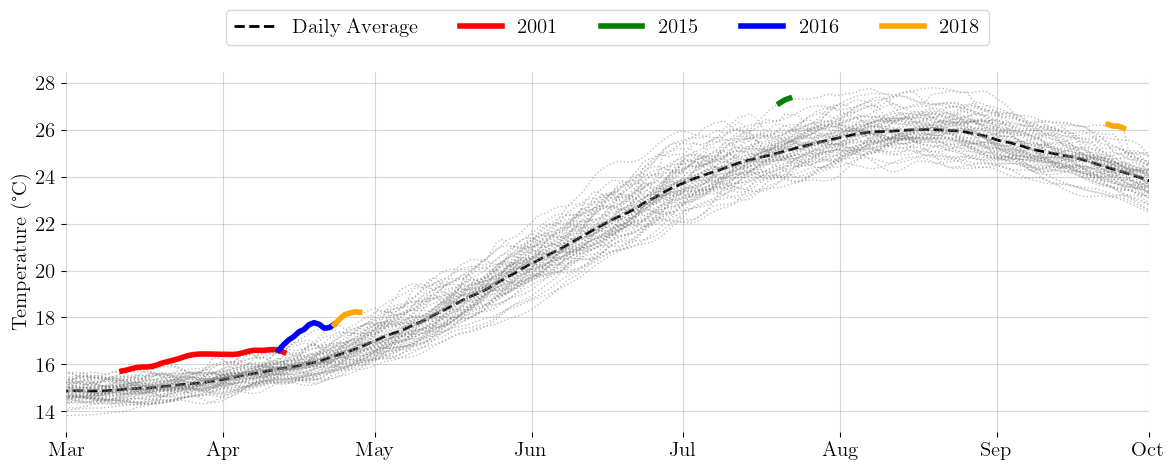

In [49]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(mean, color='black', linestyle='--', linewidth=2, label='Daily Average')


for year in range(n_year):
    ax.plot(yearly_ts[year, :], color='grey', linestyle=':', linewidth=1, alpha=0.5)

did = []
for (start, end, z) in union_bursts:
    length = end - start + 1
    i_start = start % len_year
    year = start // len_year
    xs = np.arange(i_start, i_start + length)

    if first_year + year == 2001:
        color = "red"
    elif first_year + year == 2015:
        color = "green"
    elif first_year + year == 2016:
        color = "blue"
    elif first_year + year == 2018:
        color = "orange"
    else:
        assert False
    if year in did:
        ax.plot(xs, ts[start:start + length], linewidth=4, color=color)
    else:
        ax.plot(xs, ts[start:start + length], linewidth=4, color=color, label=f"{first_year + year}")
        did.append(year)

ax.set_xticks(first_day_of_months)
ax.set_xticklabels(str_dates)
plt.xlim(first_day_of_months[2], first_day_of_months[9])

ax.set_ylabel('Temperature (°C)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.2),
          ncol=5, fancybox=True)
plt.tight_layout()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
plt.grid(alpha=.5)

plt.savefig("offline_bursts.pdf", format="pdf", bbox_inches='tight')

plt.show()


In [50]:
cm.RdYlBu_r.set_extremes

<bound method Colormap.set_extremes of <matplotlib.colors.LinearSegmentedColormap object at 0x783ca7f33e00>>

Maximum: 3.538255699967679, Minimum: -2.7743608486601032


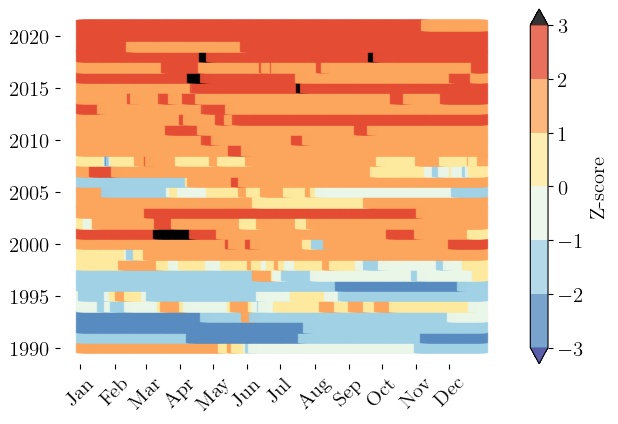

In [51]:
z_per_day = utils.compute_daily_zscore(ts, n_year, len_year)  
min_year = 1990
max_year = 2021
all_max, all_min = max(z_per_day), min(z_per_day)
print(f"Maximum: {all_max}, Minimum: {all_min}")
first_year, last_year = ts_date[0].year, ts_date[-1].year
# Discrete colorbar
abs_max = 3.5  # max(abs(all_max), abs(all_min))
levels = np.arange(-3, 3.3, 1)
norm = BoundaryNorm(boundaries=levels, ncolors=256, extend='both')
x = np.arange(len_year)
cmap = cm.RdYlBu_r
cmap.set_over("black")
plt.figure(figsize=(6.5,4.5))
for year in range(n_year):
    if max_year < year + first_year or year + first_year < min_year:
        continue
    plt.scatter(x, np.ones(len_year) * year + first_year, c=z_per_day[year * len_year:(year + 1) * len_year], 
                cmap=cmap, norm=norm, marker='s', s=50, alpha=0.8)

cbar = plt.colorbar(ticks=levels)
cbar.set_label('Z-score'), plt.xticks(first_day_of_months, str_dates, rotation=45), plt.tight_layout()
for pos in ['right', 'top', 'bottom', 'left']: plt.gca().spines[pos].set_visible(False)

plt.rcParams['font.size'] = 15
plt.savefig("mediterranean_year.pdf", format="pdf", bbox_inches='tight')

plt.show()

In [52]:
period_length = 365
threshold = 3
init_years = 30
processing_years = n_year - init_years

ts_init = ts[:init_years * period_length]
ts_processing = ts[-processing_years * period_length:]

detector = WelfordBurstDetector(
    ts=ts_init,
    n_year=init_years,
    len_year=period_length,
    threshold=threshold,
    min_length=1,
    max_length=10,
    moving=True
)

for index, obs in enumerate(ts_processing):
    detector.process(obs, index + init_years* 365)
    
online_bursts = detector.get_all_bursts()
merged_online_bursts = merge_bursts(online_bursts)
merged_online_bursts

[(14355, 14371, 1),
 (15040, 15062, 1),
 (15858, 15883, 1),
 (15935, 15941, 1),
 (19305, 19310, 1),
 (20547, 20549, 1)]

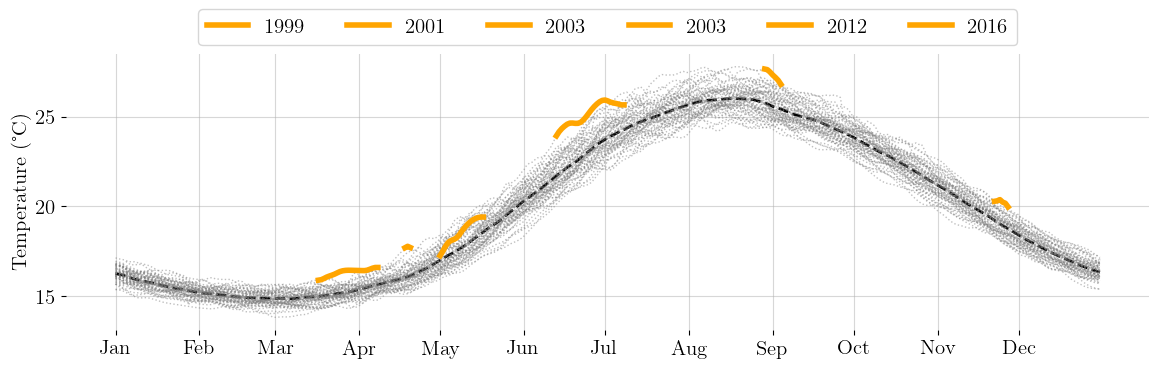

In [54]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(mean, color='black', linestyle='--', linewidth=2)

did = []
for year in range(n_year):
    ax.plot(yearly_ts[year, :], color='grey', linestyle=':', linewidth=1, alpha=0.5)

for (start, end, z) in merged_online_bursts:
    length = end - start + 1
    i_start = start % len_year
    year = start // len_year
    xs = np.arange(i_start, i_start + length)

    """
    if first_year + year == 2001:
        color = "blue"
    elif first_year + year == 2003:
        color = "red"
    elif first_year + year == 2011:
        color = "brown"
    elif first_year + year == 2012:
        color = "orange"
    elif first_year + year == 2015:
        color = "green"
    elif first_year + year == 2016:
        color = "pink"
    elif first_year + year == 2018:
        color = "purple"
    else:
        assert False
    if year in did:
        ax.plot(xs, ts[start:start + length], color=color, linewidth=4)
    else:
    """
    ax.plot(xs, ts[start:start + length], color=color, linewidth=4, label=f"{first_year + year}")
    did.append(year)

    
ax.set_xticks(first_day_of_months)
ax.set_xticklabels(str_dates)

ax.set_ylabel('Temperature (°C)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.2),
          ncol=7, fancybox=True)
plt.tight_layout()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
plt.grid(alpha=.5)

plt.rcParams['font.size'] = 15
plt.savefig("online_bursts.pdf", format="pdf", bbox_inches='tight')

plt.show()

